# Chance level C vs I: epochs mínims i mapa temps×elèctrode

**Tres preguntes:**
1. Quants epochs calen (aprox.) per superar el chance level en C vs I?
2. Per a cada elèctrode, a partir de quin instant se supera chance level?
3. A nivell de grup, on i quan podem afirmar que l'accuracy supera chance?

**Metodologia:**
- Surrogate per permutació d'etiquetes, **per subjecte × elèctrode × finestra temporal**.
- ΔAcc = Acc_real(t) − Acc_chance(t)
- Contrast de grup: paired t-test one-tailed vectoritzat + FDR per cel·la (canal, t).
- Paral·lelisme: `joblib.Parallel` (N_JOBS) sobre subjectes.
- Els tensors intermedis es desen a disc per evitar recalcular si el kernel cau.


In [2]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
    drive.mount("/content/drive")
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "c_vs_i"
CACHE_DIR = ANALYSIS_DIR / "cache"
TABLES_DIR = ANALYSIS_DIR / "tables"
FIGURES_DIR = ANALYSIS_DIR / "figures"
for folder in (DATA_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, CACHE_DIR, TABLES_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
}

print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Projecte: {PROJECT_DIR}")
print(f"Dades: {DATA_DIR}")
print(f"Resultats: {ANALYSIS_DIR}")
print(f"Fitxers .fif trobats: {len(DATA_FILES)}")
print(f"Cores disponibles: {cpu_count()}")

Entorn: Local
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i
Fitxers .fif trobats: 47
Cores disponibles: 8


## Configuració

In [23]:
TASK_TAG = "c_vs_i_FCz_theta_Oz_alpha"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.5, 1.0)

# Definició compacta: (elèctrode, banda)
TARGET_BAND_CHANNELS = (
    ("FCz", "theta"),
    ("Oz", "alpha"),
)
BAND_RANGES = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}
CHANNEL_MODE = [f"{ch}-{band}" for ch, band in TARGET_BAND_CHANNELS]

# Subjectes: sempre des de CSV, i retallats amb MAX_SUBJECTS
SELECTED_SUBJECTS_CSV = PROJECT_DIR / "04_Anàlisi" / "01_exploracio" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 12  # None = tots els del CSV
UNDERSAMPLE_CLASSES = True  # balanceja C/I per subjecte

# Directoris de sortida
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"map_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.npz"
EPOCHS_CSV = TABLES_DIR / "epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv"
ONSET_CSV = TABLES_DIR / "onset_summary_c_vs_i_FCz_theta_Oz_alpha.csv"

# Mapa temps×elèctrode
MAP_WINDOW_SEC = 0.500  # amplada finestra temporal (s)
MAP_STEP_SEC = 0.02  # pas (s)
MAP_CV_MAX_SPLITS = 5  # màxim folds CV

# Surrogate
N_PERM_SURROGATE = 50

# Graella epochs
EPOCHS_GRID = [x for x in range(20, 200, 10)]
N_REPEATS_EPOCHS = 15
N_JOBS = 6

RANDOM_SEED = 42

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"CACHE_MAP_FILE: {CACHE_MAP_FILE}")
print(f"TARGET_BAND_CHANNELS: {TARGET_BAND_CHANNELS}")
print(f"BAND_RANGES: {BAND_RANGES}")

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\subjectes_seleccionats.csv
CACHE_MAP_FILE: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub12.npz
TARGET_BAND_CHANNELS: (('FCz', 'theta'), ('Oz', 'alpha'))
BA

## 1 · Càrrega de dades

In [4]:
def load_chance_epochs():
    """Carrega els primers MAX_SUBJECTS del CSV de selecció i construeix canals derivats."""
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subjecte"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))  # deduplicació preservant ordre
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Subjectes seleccionats a carregar: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}
    derived_ch_names = [f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS]

    X_blocks, y_blocks, subj_blocks = [], [], []
    skipped = []

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=True)

        # Alguns fitxers venen amb unitats EEG a zero; normalitzem a volts abans de canviar el tipus.
        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        # Conserva només canals EEG; si el fitxer no porta tipus EEG, força'ls a EEG.
        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
        i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]
        ep = ep[c_names + i_names].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        events = ep.events[:, 2]
        c_codes = [ep.event_id[n] for n in c_names]
        y_s = np.where(np.isin(events, c_codes), 0, 1).astype(np.int8)

        n_c, n_i = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_c, n_i) == 0:
            skipped.append(f"{fif_path.name}: classe buida (C={n_c}, I={n_i})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_c, n_i)
            idx_c = np.where(y_s == 0)[0]
            idx_i = np.where(y_s == 1)[0]
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            keep_idx = np.concatenate(
                [
                    rng.choice(idx_c, n_min, replace=False),
                    rng.choice(idx_i, n_min, replace=False),
                ]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        band_arrays = []
        missing_specs = []
        for ch_name, band in TARGET_BAND_CHANNELS:
            if ch_name not in ep.ch_names:
                missing_specs.append(f"{ch_name}-{band}")
                continue
            if band not in BAND_RANGES:
                raise ValueError(f"Banda no suportada: {band}. Defineix-la a BAND_RANGES.")

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick([ch_name])
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                fir_design="firwin",
                phase="zero-double",
                verbose=False,
            )
            x_band = ep_band.get_data()[:, 0, :].astype(np.float32)
            band_arrays.append(x_band)

        if missing_specs or len(band_arrays) != len(TARGET_BAND_CHANNELS):
            skipped.append(f"{fif_path.name}: falten especificacions requerides ({', '.join(missing_specs)})")
            continue

        X_s = np.stack(band_arrays, axis=1)  # (trials, n_specs, times)
        X_blocks.append(X_s)
        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    X = np.concatenate(X_blocks, axis=0)
    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)
    ch_names = derived_ch_names
    times = np.array(ep.times, dtype=np.float32)

    print(f"Mostres totals: {len(y)} | C={(y==0).sum()} | I={(y==1).sum()}")
    print(f"Subjectes carregats: {len(np.unique(subj_list))} | Canals derivats: {ch_names} | Temps: {len(times)}")
    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    return X, y, subj_list, ch_names, times


X, y, subj_list, ch_names, times = load_chance_epochs()

Subjectes seleccionats a carregar: 12
Mostres totals: 4784 | C=2392 | I=2392
Subjectes carregats: 12 | Canals derivats: ['FCz-theta', 'Oz-alpha'] | Temps: 251


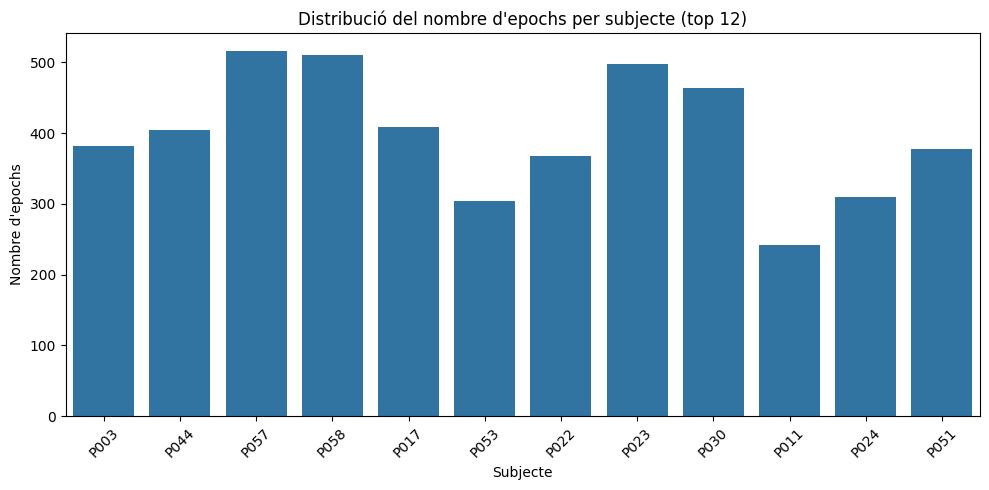

In [37]:
# Histograma de nombre d'epochs per subjecte
plt.figure(figsize=(10, 5))
sns.countplot(x=subj_list)
plt.xticks(rotation=45)
plt.xlabel("Subjecte")
plt.ylabel("Nombre d'epochs")
plt.title("Distribució del nombre d'epochs per subjecte (top 12)")
plt.tight_layout()
plt.show()

## 2 · Funcions de CV i surrogate

### Decisions de disseny

**Per quin nivell es calcula el surrogate?**  
El surrogate s'avalua **a la mateixa finestra temporal** que l'accuracy real.  
D'aquesta manera, ΔAcc(t) = Acc_real(t) − Acc_chance(t) és una comparació neta:
ambdues xifres es basen en les mateixes mostres temporals i el mateix classificador.

**Quantes permutacions?**  
`N_PERM_SURROGATE` (configurable a la cel·la 1). Per a inferència final usa ≥200; per a
proves ràpides, 50 és acceptable.

**Paired t-test de grup:**  
Per a cada cel·la (canal, t) comparem el vector d'Acc_real dels subjectes vs el vector
d'Acc_chance. Amb N≥6 subjectes vàlids, el test t aparellat és adequat.  
Criteri robust final: p < 0.05 **i** ΔAcc_grupal > 0 **i** hit-rate ≥ 0.5.


In [6]:
def choose_n_splits(y_s, max_splits=5):
    """Folds CV en funció del mínim de la classe menys freqüent."""
    return max(2, min(max_splits, int(np.bincount(y_s).min())))


def make_clf():
    return make_pipeline(
        StandardScaler(),
        LogisticRegressionCV(
            Cs=list(np.logspace(-4, 4, 9)),
            cv=3,
            penalty="l2",
            solver="liblinear",
            scoring="accuracy",
            max_iter=2000,
            random_state=RANDOM_SEED,
            refit=True,
        ),
    )


def cv_accuracy(X_feat, y_s, n_splits, seed=RANDOM_SEED):
    """Accuracy mitjana en CV estratificat.
    X_feat: (n_trials, n_features). Pot ser 1D per mostra.
    """
    if X_feat.ndim == 1:
        X_feat = X_feat[:, None]
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = make_clf()
    accs = []
    for tr, te in cv.split(X_feat, y_s):
        clf.fit(X_feat[tr], y_s[tr])
        accs.append(float(np.mean(clf.predict(X_feat[te]) == y_s[te])))
    return float(np.mean(accs))


def surrogate_distribution(X_feat, y_s, n_splits, n_perm, seed=RANDOM_SEED):
    """Distribució surrogate per permutació d'etiquetes.
    Retorna array de shape (n_perm,) amb les accuracies permutades.
    """
    rng = np.random.default_rng(seed)
    perm_accs = np.empty(n_perm, dtype=np.float32)
    for p in range(n_perm):
        y_perm = rng.permutation(y_s)
        perm_accs[p] = cv_accuracy(X_feat, y_perm, n_splits, seed=seed + p + 1)
    return perm_accs


def balanced_sample(y_s, n_total, rng):
    """Retorna índexs balancejats (n_total//2 per classe) o None si no hi ha prou."""
    n2 = n_total // 2
    idx_c = np.where(y_s == 0)[0]
    idx_i = np.where(y_s == 1)[0]
    if len(idx_c) < n2 or len(idx_i) < n2:
        return None
    out = np.concatenate([rng.choice(idx_c, n2, replace=False), rng.choice(idx_i, n2, replace=False)])
    rng.shuffle(out)
    return out

## 3 · Worker per subjecte (paral·lelitzat)

La funció `_process_subject` encapsula **tot el treball** d'un subjecte:

1. Per a cada finestra temporal, calcula Acc_real i la distribució surrogate **a la mateixa finestra**.
2. Retorna `real_arr[ch, t]`, `chance_mean_arr[ch, t]`, `chance_q95_arr[ch, t]`.

Desacoblar el surrogate per finestra és la **clau de la correctesa**:
usar un surrogate global (finestra completa) com a baseline per finestres individuals
seria inconsistent si la senyalització varia molt al llarg del temps.


In [7]:
def _process_subject(si, subj, X_all, y_all, subj_list_all, ch_names_l, starts, stops):
    """Processa un subjecte: per a cada (canal, finestra) calcula
    acc_real i la distribució surrogate."""
    idx_s = np.where(subj_list_all == subj)[0]
    Xs, ys = X_all[idx_s], y_all[idx_s]

    n_ch = len(ch_names_l)
    n_w = len(starts)

    real_arr = np.full((n_ch, n_w), np.nan, dtype=np.float32)
    surr_mean = np.full((n_ch, n_w), np.nan, dtype=np.float32)
    surr_q95 = np.full((n_ch, n_w), np.nan, dtype=np.float32)

    if len(np.unique(ys)) < 2:
        return real_arr, surr_mean, surr_q95

    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)
    base_seed = RANDOM_SEED + 10_000 * (si + 1)

    for ch_idx in range(n_ch):
        for wi, (s, e) in enumerate(zip(starts, stops)):
            X_raw = Xs[:, ch_idx, s:e]

            # Potència mitjana a la finestra
            # X_feat = np.mean(X_raw**2, axis=-1, keepdims=True)

            # Alternativa: Hilbert envelope
            envelope = np.abs(hilbert(X_raw, axis=-1))
            X_feat = np.mean(envelope, axis=-1, keepdims=True)

            win_seed = base_seed + wi * 1000 + ch_idx
            real_arr[ch_idx, wi] = cv_accuracy(X_feat, ys, n_splits, seed=win_seed)
            dist = surrogate_distribution(X_feat, ys, n_splits, n_perm=N_PERM_SURROGATE, seed=win_seed + 1)
            surr_mean[ch_idx, wi] = float(dist.mean())
            surr_q95[ch_idx, wi] = float(np.quantile(dist, 0.95))

    return real_arr, surr_mean, surr_q95

## 4 · Quants epochs calen per superar chance? (graella)

Aquí la feature és la sèrie temporal completa (`ANALYSIS_WINDOW`) de cada canal,
i es submostregen n_epochs balancejats per estudiar com evoluciona l'accuracy.

El surrogate es calcula **a la mateixa submostra** per ser consistent.


In [8]:
def _epochs_worker(si, subj, X_all, y_all, subj_list_all, ch_names_l):
    """Per a un subjecte, recorre EPOCHS_GRID × canals i calcula
    acc_real_mean, chance_mean, chance_q95 amb submostreig repetit."""
    idx_s = np.where(subj_list_all == subj)[0]
    Xs, ys = X_all[idx_s], y_all[idx_s]

    if len(np.unique(ys)) < 2:
        return []

    rows = []
    rng = np.random.default_rng(RANDOM_SEED + si * 9973)
    n_splits = choose_n_splits(ys, max_splits=MAP_CV_MAX_SPLITS)

    for ch_idx, ch_name in enumerate(ch_names_l):
        X_ch = Xs[:, ch_idx, :]  # (trials, times)
        for n_total in EPOCHS_GRID:
            if n_total % 2 != 0:
                continue
            real_accs = []
            perm_all = []

            for rep in range(N_REPEATS_EPOCHS):
                idx_sub = balanced_sample(ys, n_total, rng)
                if idx_sub is None:
                    continue

                X_raw = X_ch[idx_sub]

                # Potència mitjana de tota la finestra d'anàlisi
                # X_feat = np.mean(X_raw**2, axis=-1, keepdims=True)

                # Alternativa: Hilbert envelope
                envelope = np.abs(hilbert(X_raw, axis=-1))
                X_feat = np.mean(envelope, axis=-1, keepdims=True)

                seed_r = RANDOM_SEED + si * 9973 + ch_idx * 997 + n_total + rep
                real_accs.append(cv_accuracy(X_feat, ys[idx_sub], n_splits, seed=seed_r))
                perm_dist = surrogate_distribution(
                    X_feat,
                    ys[idx_sub],
                    n_splits,
                    n_perm=max(20, N_PERM_SURROGATE // 5),
                    seed=seed_r + 1,
                )
                perm_all.append(perm_dist)

            if not real_accs:
                continue
            perm_concat = np.concatenate(perm_all) if perm_all else np.array([0.5])

            rows.append(
                {
                    "subject": subj,
                    "electrode": ch_name,
                    "n_epochs_total": int(n_total),
                    "acc_real_mean": float(np.mean(real_accs)),
                    "acc_real_std": float(np.std(real_accs)),
                    "acc_chance_mean": float(perm_concat.mean()),
                    "acc_chance_q95": float(np.quantile(perm_concat, 0.95)),
                    "delta_acc": float(np.mean(real_accs) - perm_concat.mean()),
                    "delta_acc_q95": float(np.mean(real_accs) - np.quantile(perm_concat, 0.95)),
                }
            )
    return rows

### 4a Execució (paral·lel per subjectes)

In [9]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}_"
    f"u{int(UNDERSAMPLE_CLASSES)}_perm{N_PERM_SURROGATE}.csv"
)

if not RECALCULAR_CHANCE_LEVEL and CACHE_EPOCHS.exists():
    print(f"Carregant df_epochs des de cache: {CACHE_EPOCHS}")
    df_epochs = pd.read_csv(CACHE_EPOCHS)
else:
    print(
        f"Graella epochs — {len(subject_ids)} subj × {len(ch_names)} canals × "
        f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
    )

    all_rows = Parallel(n_jobs=N_JOBS, verbose=5)(
        delayed(_epochs_worker)(si, subj, X, y, subj_list, ch_names) for si, subj in enumerate(subject_ids)
    )

    df_epochs = (
        pd.DataFrame([r for rows in all_rows for r in rows])
        .sort_values(["subject", "electrode", "n_epochs_total"])
        .reset_index(drop=True)
    )

    df_epochs.to_csv(CACHE_EPOCHS, index=False)
    print(f"Desat cache: {CACHE_EPOCHS}")

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Desat taula: {EPOCHS_CSV}")
df_epochs.head(10)

Carregant df_epochs des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\epochs_grid_c_vs_i_FCz_theta_Oz_alpha_sub12_u1_perm50.csv
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables\epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P003,FCz-theta,20,0.546667,0.146591,0.496167,0.700000,0.050500,-0.153333
1,P003,FCz-theta,30,0.526667,0.143604,0.496444,0.666667,0.030222,-0.140000
2,P003,FCz-theta,40,0.551667,0.075535,0.491917,0.650000,0.059750,-0.098333
3,P003,FCz-theta,50,0.565333,0.091350,0.495200,0.640000,0.070133,-0.074667
4,P003,FCz-theta,60,0.551111,0.050723,0.492556,0.616667,0.058556,-0.065556
5,P003,FCz-theta,70,0.586667,0.040226,0.505476,0.614286,0.081190,-0.027619
6,P003,FCz-theta,80,0.550833,0.029744,0.495917,0.612500,0.054917,-0.061667
7,P003,FCz-theta,90,0.545185,0.064593,0.496667,0.611111,0.048519,-0.065926
8,P003,FCz-theta,100,0.563333,0.057581,0.503500,0.600000,0.059833,-0.036667
9,P003,FCz-theta,110,0.553333,0.075760,0.497727,0.590909,0.055606,-0.037576


In [10]:
# Mostrar df_epochs ordenats per delta_acc_q95 descendent
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P044,Oz-alpha,180,0.620000,0.017662,0.493704,0.561111,0.126296,0.058889
1,P003,Oz-alpha,120,0.631111,0.036192,0.499278,0.575417,0.131833,0.055695
2,P044,Oz-alpha,170,0.628627,0.030366,0.502333,0.576471,0.126294,0.052157
3,P044,Oz-alpha,140,0.630000,0.025044,0.497714,0.578928,0.132286,0.051072
4,P044,Oz-alpha,190,0.618596,0.018117,0.499421,0.568421,0.119175,0.050175
...,...,...,...,...,...,...,...,...,...
427,P058,Oz-alpha,20,0.493333,0.142439,0.496667,0.700000,-0.003333,-0.206667
428,P011,Oz-alpha,20,0.493333,0.150407,0.489500,0.700000,0.003833,-0.206667
429,P053,FCz-theta,20,0.470000,0.097980,0.488167,0.700000,-0.018167,-0.230000
430,P053,Oz-alpha,20,0.463333,0.143139,0.504833,0.700000,-0.041500,-0.236667


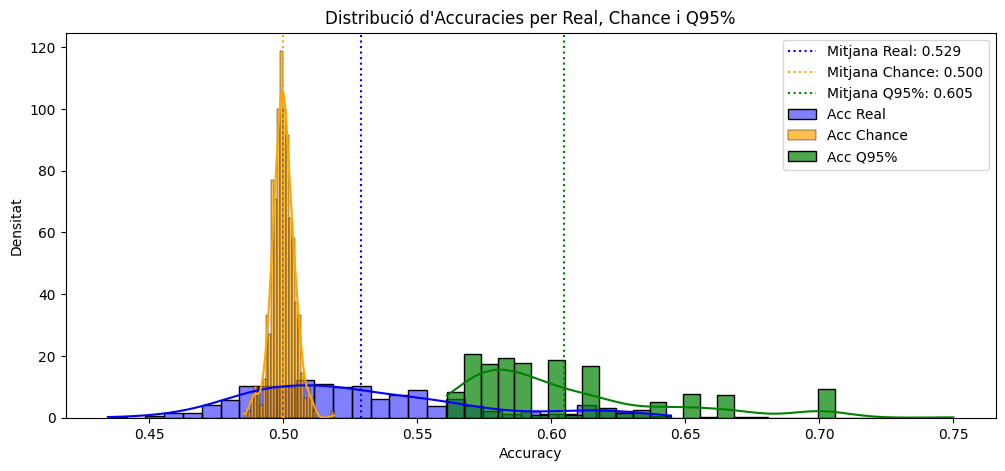

In [11]:
# Histograma acc_real_mean, acc_chance_mean i acc_chance_q95 amb seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribució d'Accuracies per Real, Chance i Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Ensenya mitjanes dels tres grups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Mitjana Real: {mean_real:.3f}")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mitjana Chance: {mean_chance:.3f}")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Mitjana Q95%: {mean_q95:.3f}")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

### 4b · Resum numèric epochs → accuracy (sense figures)

Aquesta cel·la deixa només el resum numèric de la graella.
Totes les figures queden centralitzades a l'apartat 7.

In [12]:
# Resum numèric de la graella d'epochs
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Resum de rendiment (graella epochs):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Subjectes únics: {df_epochs['subject'].nunique()}")
print(f"- Elèctrodes únics: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Acc real mitjana global: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Chance q95 mitjana global: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Mínim d'epochs per superar q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinacions que superen q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- Cap combinació supera el chance q95 en la graella actual.")

display(grp.head(10))

Resum de rendiment (graella epochs):
- Files totals: 432
- Subjectes únics: 12
- Elèctrodes únics: 2
- n_epochs provats: [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190]
- Acc real mitjana global: 0.5292
- Chance q95 mitjana global: 0.6049
- Mínim d'epochs per superar q95: 70
- Combinacions que superen q95: 45/432 (10.4%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.517917,0.132364,0.497507,0.702187
1,30,0.521204,0.108590,0.500787,0.668194
2,40,0.521597,0.090679,0.499736,0.649010
3,50,0.526167,0.083174,0.499689,0.633375
4,60,0.521620,0.074167,0.500683,0.620312
5,70,0.532659,0.068530,0.500095,0.611429
6,80,0.530903,0.060069,0.500715,0.606901
7,90,0.523580,0.057237,0.499653,0.597361
8,100,0.527861,0.056985,0.500097,0.595062
9,110,0.533737,0.050063,0.499202,0.591686


## 5 · Mapa temps×elèctrode (càlcul paral·lel)

### Nota sobre les features per finestra
Cada finestra de `MAP_WINDOW_SEC` és classificada usant **tots els punts temporals
de la finestra** com a features (matriu `trials × win_samples` al LR).
Això és molt més informatiu que usar la mitjana (1 feature), però augmenta el
cost computacional — d'aquí la necessitat del paral·lelisme.


In [13]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals
time_step = float(np.median(np.diff(times)))
sfreq_est = 1.0 / time_step
win_samples = max(2, int(round(MAP_WINDOW_SEC * sfreq_est)))
step_samples = max(1, int(round(MAP_STEP_SEC * sfreq_est)))

starts = np.arange(0, len(times) - win_samples + 1, step_samples)
stops = starts + win_samples
window_centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
n_w, n_ch = len(window_centers), len(ch_names)

print(f"Finestres: {n_w} | amplada={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Canals: {n_ch} | Subjectes: {len(subject_ids)}")
print(f"Features per finestra: {win_samples} punts × 1 canal")
print(
    f"Total de surrogates a calcular: {len(subject_ids)} × {n_ch} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_ch*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 1 | amplada=500ms, pas=20ms
Canals: 2 | Subjectes: 12
Features per finestra: 250 punts × 1 canal
Total de surrogates a calcular: 12 × 2 × 1 × 50 = 1,200


In [22]:
CACHE_MAP_FILE

WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/04_Anàlisi/c_vs_i/cache/map_c_vs_i_FCz_theta_Oz_alpha_sub12.csv')

In [26]:
subject_ids = pd.unique(subj_list).tolist()

print("Executant mapa temps×clúster (paral·lel per subjectes) …")
print(f"Subjectes: {len(subject_ids)}")

if not RECALCULAR_CHANCE_LEVEL and CACHE_MAP_FILE.exists():
    print(f"Carregant mapa temps×clúster des de cache: {CACHE_MAP_FILE}")
    map_data = np.load(CACHE_MAP_FILE)
    real_map = map_data["real_map"]
    surr_mean = map_data["surr_mean"]
    surr_q95 = map_data["surr_q95"]
else:
    print("Recalculant mapa temps×clúster (permutacions) …")
    results = Parallel(n_jobs=N_JOBS)(
        delayed(_process_subject)(si, subj, X, y, subj_list, ch_names, starts, stops)
        for si, subj in enumerate(subject_ids)
    )

    # Reassembla tensors (n_subj, n_bands, n_w)
    real_map = np.stack([r[0] for r in results], axis=0)  # (S, C, W)
    surr_mean = np.stack([r[1] for r in results], axis=0)
    surr_q95 = np.stack([r[2] for r in results], axis=0)
    np.savez_compressed(CACHE_MAP_FILE, real_map=real_map, surr_mean=surr_mean, surr_q95=surr_q95)
    print(f"Desat mapa temps×clúster a cache: {CACHE_MAP_FILE}")

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, clúster, finestra)")

Executant mapa temps×clúster (paral·lel per subjectes) …
Subjectes: 12
Recalculant mapa temps×clúster (permutacions) …
Desat mapa temps×clúster a cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub12.npz
Tensors shape: real_map=(12, 2, 1)  (subj, clúster, finestra)


## 6 · Estadística de grup: paired t-test per cel·la (canal, t)

Per a cada cel·la $(ch, t)$ comparem:
- **real_map[:, ch, t]**: accuracy real de cada subjecte
- **surr_mean[:, ch, t]**: accuracy de chance (surrogate mean) del mateix subjecte

Hipòtesi H₁ (one-tailed): Acc_real > Acc_chance → només p/2 si t > 0.
Criteri final robust: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50`.


In [31]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)

for ch_idx in range(n_ch):
    for wi in range(n_w):
        a = real_map[:, ch_idx, wi]
        b = surr_mean[:, ch_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[ch_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[ch_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_ch, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset per elèctrode: primer instant amb superació significativa
onset_time_per_ch = np.full(n_ch, np.nan, dtype=np.float32)
for ch_idx in range(n_ch):
    sig_idx = np.where(sig_map[ch_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[ch_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Cel·les significatives (p<0.05, ΔAcc>0): {n_sig} / {n_ch*n_w}")
print(f"Cel·les robustes (+hit-rate≥0.5):         {n_rob} / {n_ch*n_w}")

Cel·les significatives (p<0.05, ΔAcc>0): 2 / 2
Cel·les robustes (+hit-rate≥0.5):         1 / 2


## 7 · Visualitzacions (centralitzades)

Totes les figures del notebook es concentren aquí:
- distribucions globals
- corbes epochs→accuracy
- comparativa FCz-theta vs Oz-alpha
- dinàmica temporal i taxa de superació de q95

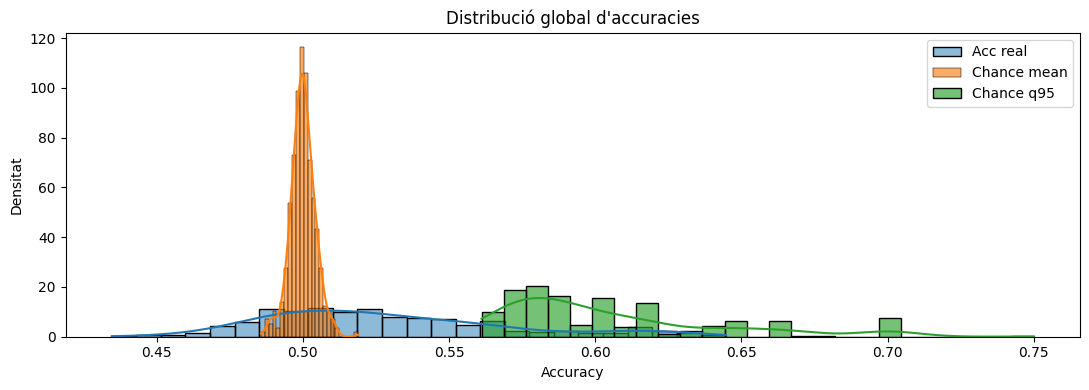

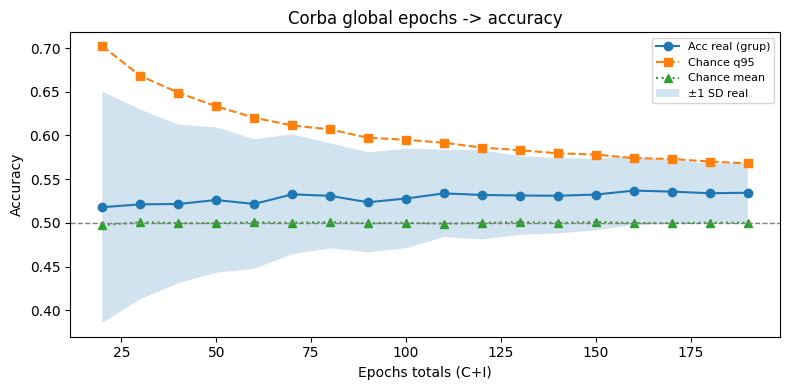

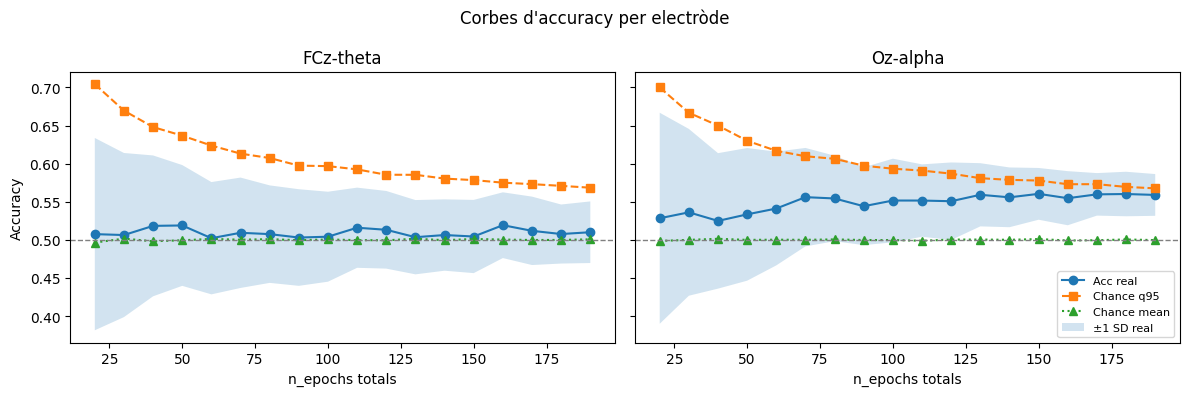

In [32]:
target_electrodes = ["FCz-theta", "Oz-alpha"]
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

if df_two.empty:
    raise RuntimeError("No hi ha files de df_epochs per FCz-theta/Oz-alpha.")

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(df_epochs, x="acc_real_mean", color="tab:blue", label="Acc real", kde=True, stat="density", bins=25)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label="Chance mean",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label="Chance q95",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Distribució global d'accuracies")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.show()

# 7b) Corba epochs -> accuracy (grup)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (C+I)")
plt.ylabel("Accuracy")
plt.title("Corba global epochs -> accuracy")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7c) Corbes per electròde (només FCz-theta i Oz-alpha)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, elec in zip(axes, target_electrodes):
    d = df_two[df_two["electrode"] == elec]
    g = (
        d.groupby("n_epochs_total")
        .agg(
            acc_real_mean=("acc_real_mean", "mean"),
            acc_real_std=("acc_real_std", "mean"),
            acc_chance_q95=("acc_chance_q95", "mean"),
            acc_chance_mean=("acc_chance_mean", "mean"),
        )
        .reset_index()
    )

    ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
    ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
    ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
    ax.fill_between(
        g["n_epochs_total"],
        g["acc_real_mean"] - g["acc_real_std"],
        g["acc_real_mean"] + g["acc_real_std"],
        alpha=0.2,
        label="±1 SD real",
    )
    ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
    ax.set_title(elec)
    ax.set_xlabel("n_epochs totals")

axes[0].set_ylabel("Accuracy")
axes[1].legend(fontsize=8, loc="lower right")
plt.suptitle("Corbes d'accuracy per electròde", fontsize=12)
plt.tight_layout()
plt.show()

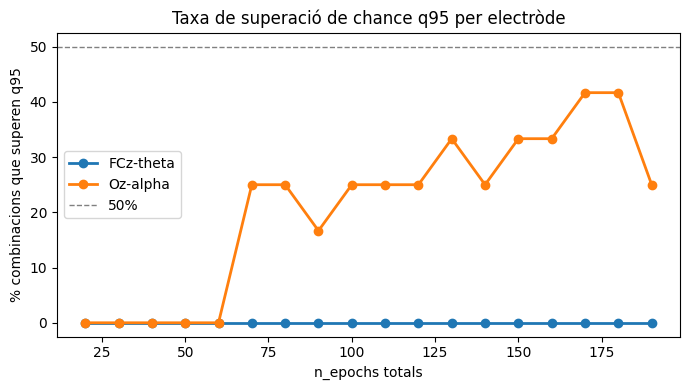

Dinàmica temporal no informativa: només hi ha 1 finestra temporal. Per veure corbes, redueix MAP_WINDOW_SEC i/o MAP_STEP_SEC i recalcula seccions 5 i 6.


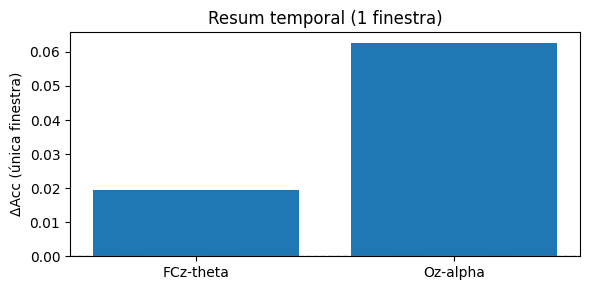


=== RESUM FINAL: FCz-theta vs Oz-alpha ===

FCz-theta:
  - Combinacions que superen q95: 0/216 (0.0%)
  - ΔAcc mitjà: 0.0094
  - Acc màxima: 0.5867

Oz-alpha:
  - Combinacions que superen q95: 45/216 (20.8%)
  - ΔAcc mitjà: 0.0490
  - Acc màxima: 0.6447



In [33]:
# 7d) Taxa de superació q95 per electròde
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"]
    .mean()
    .unstack("electrode")
    .reindex(columns=target_electrodes)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in target_electrodes:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("n_epochs totals")
ax.set_ylabel("% combinacions que superen q95")
ax.set_title("Taxa de superació de chance q95 per electròde")
ax.legend()
plt.tight_layout()
plt.show()

# 7e) Dinàmica temporal (si el mapa temps×elèctrode està calculat)
needed = ["window_centers", "mean_delta_map", "hit_rate_map", "ch_names"]
if all(name in globals() for name in needed):
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}

    valid_targets = [e for e in target_electrodes if e in ch_to_idx]
    if len(valid_targets) == 0:
        print("No hi ha canals objectiu presents a ch_names per la dinàmica temporal.")
    elif len(window_centers) < 2:
        print(
            "Dinàmica temporal no informativa: només hi ha 1 finestra temporal. "
            "Per veure corbes, redueix MAP_WINDOW_SEC i/o MAP_STEP_SEC i recalcula seccions 5 i 6."
        )
        plt.figure(figsize=(6, 3))
        bars = []
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            bars.append(float(mean_delta_map[ci, 0]))
        plt.bar(valid_targets, bars)
        plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
        plt.ylabel("ΔAcc (única finestra)")
        plt.title("Resum temporal (1 finestra)")
        plt.tight_layout()
        plt.show()
    else:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
            axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

        axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_ylabel("ΔAcc (real - chance)")
        axes[0].set_title("Dinàmica temporal per electròde")
        axes[0].legend()

        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
        axes[1].set_ylabel("Hit-rate")
        axes[1].set_xlabel("Temps (s)")
        axes[1].legend()

        plt.tight_layout()
        plt.show()
else:
    print("Per mostrar la dinàmica temporal, executa primer les seccions 5 i 6.")

print("\n=== RESUM FINAL: FCz-theta vs Oz-alpha ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec}:")
    print(f"  - Combinacions que superen q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - ΔAcc mitjà: {avg_delta:.4f}")
    print(f"  - Acc màxima: {max_acc:.4f}")
    print()

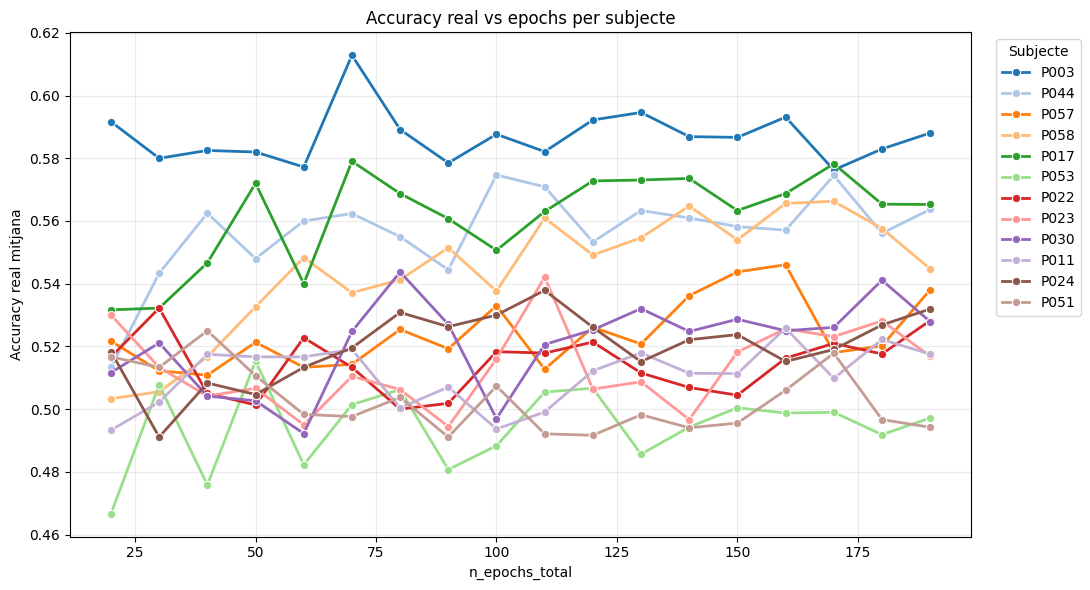

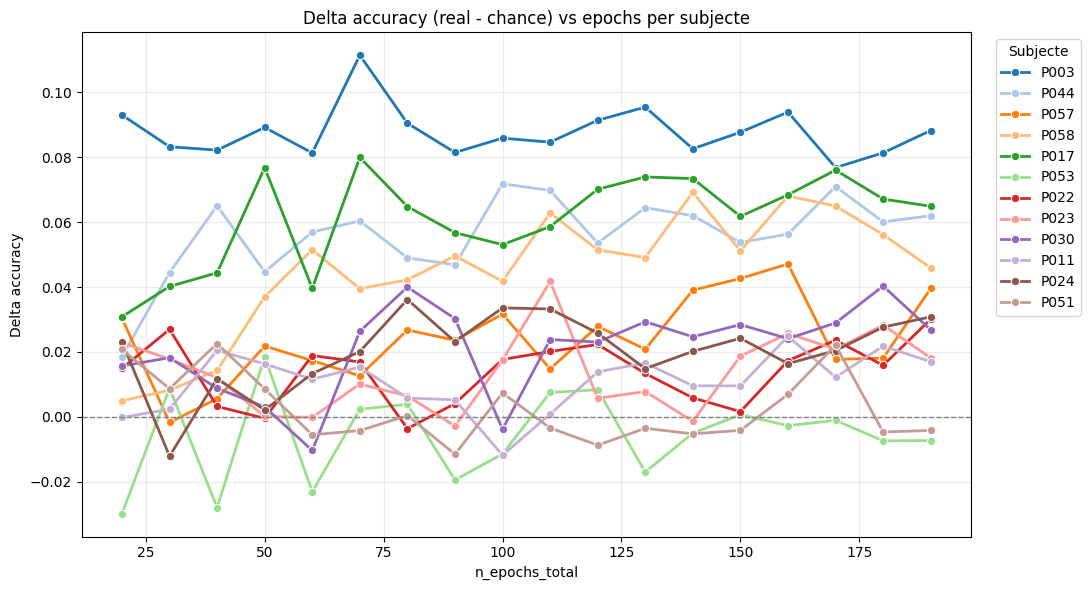

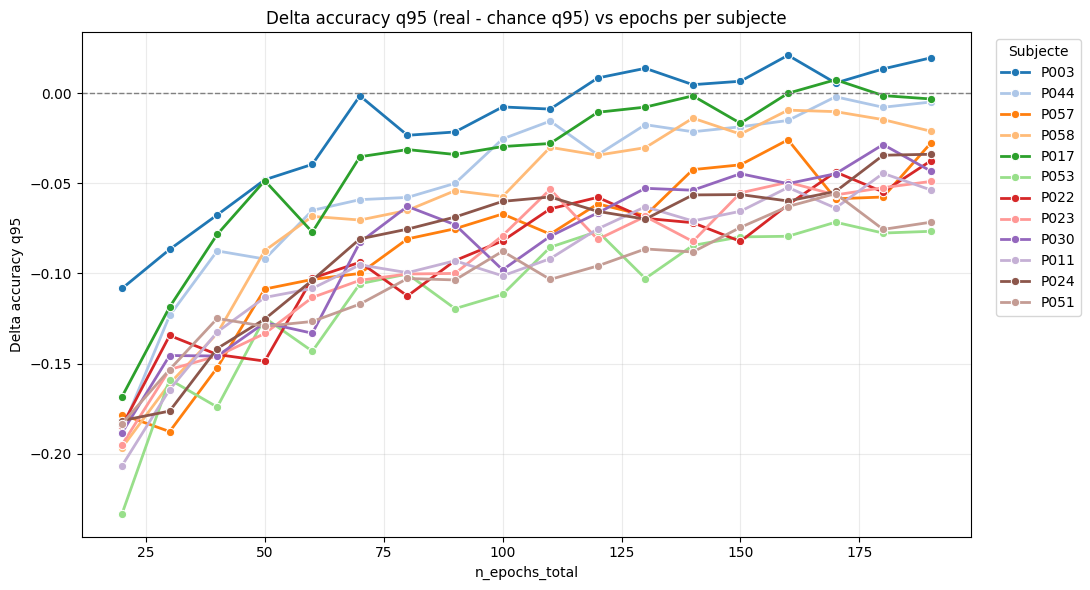

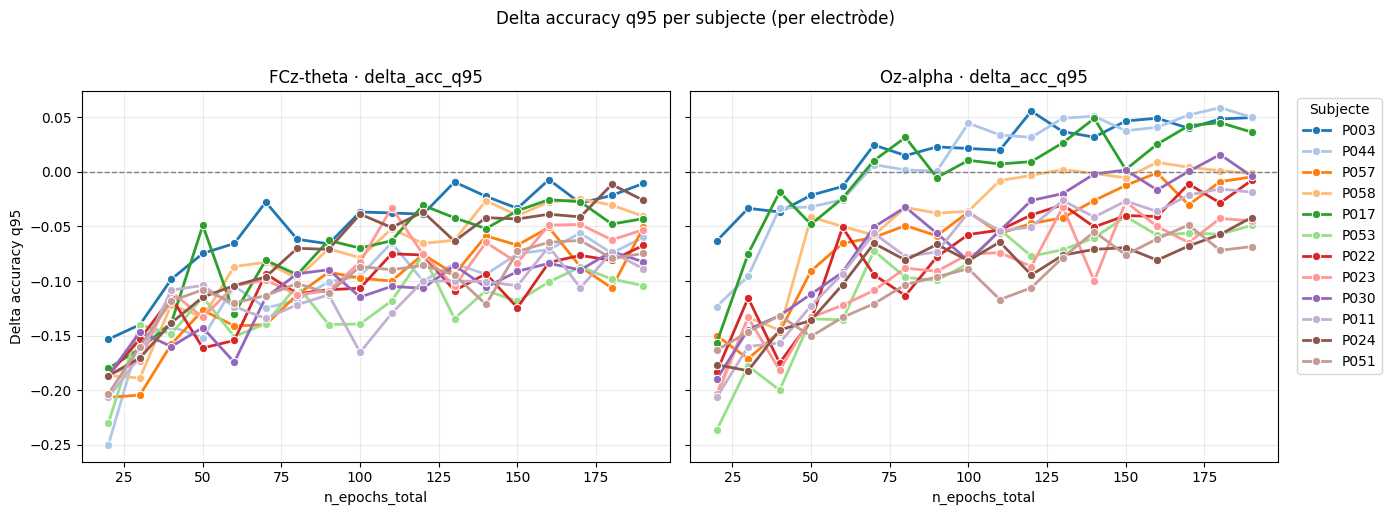

In [ ]:
# Visualitzacions per subjecte (versió simplificada)
subject_order = [s for s in pd.unique(subj_list) if s in df_epochs["subject"].unique()]


def agg_by_subject(metric):
    return (
        df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)[metric]
        .mean()
        .sort_values(["subject", "n_epochs_total"])
    )


def plot_subject_lines(df_plot, y_col, title, y_label, ylim=None):
    plt.figure(figsize=(11, 6))
    sns.lineplot(
        data=df_plot,
        x="n_epochs_total",
        y=y_col,
        hue="subject",
        hue_order=subject_order,
        palette="tab20",
        marker="o",
        linewidth=2,
    )
    if y_col in ["delta_acc", "delta_acc_q95"]:
        plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    plt.title(title)
    plt.xlabel("n_epochs_total")
    plt.ylabel(y_label)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.grid(alpha=0.25)
    plt.legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


# 1) Accuracy real
plot_subject_lines(
    agg_by_subject("acc_real_mean"),
    y_col="acc_real_mean",
    title="Accuracy real vs epochs per subjecte",
    y_label="Accuracy real mitjana",
)

# 2) Delta accuracy
plot_subject_lines(
    agg_by_subject("delta_acc"),
    y_col="delta_acc",
    title="Delta accuracy (real - chance) vs epochs per subjecte",
    y_label="Delta accuracy",
)

# 3) Delta accuracy q95
plot_subject_lines(
    agg_by_subject("delta_acc_q95"),
    y_col="delta_acc_q95",
    title="Delta accuracy q95 (real - chance q95) vs epochs per subjecte",
    y_label="Delta accuracy q95",
)

# 4) Delta accuracy q95 separat per electròde (2 subplots)
preferred_electrodes = ["FCz-theta", "Oz-alpha"]
plot_electrodes = [e for e in preferred_electrodes if e in df_epochs["electrode"].unique()]
if len(plot_electrodes) == 0:
    plot_electrodes = df_epochs["electrode"].dropna().unique().tolist()[:2]

df_subj_delta_q95_elec = (
    df_epochs[df_epochs["electrode"].isin(plot_electrodes)]
    .groupby(["subject", "electrode", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["electrode", "subject", "n_epochs_total"])
)

fig, axes = plt.subplots(1, len(plot_electrodes), figsize=(7 * len(plot_electrodes), 5), sharey=True)
if len(plot_electrodes) == 1:
    axes = [axes]

for i, (ax, elec) in enumerate(zip(axes, plot_electrodes)):
    d = df_subj_delta_q95_elec[df_subj_delta_q95_elec["electrode"] == elec]
    sns.lineplot(
        data=d,
        x="n_epochs_total",
        y="delta_acc_q95",
        hue="subject",
        hue_order=subject_order,
        palette="tab20",
        marker="o",
        linewidth=2,
        ax=ax,
    )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{elec} · delta_acc_q95")
    ax.set_xlabel("n_epochs_total")
    ax.grid(alpha=0.25)
    if i == 0:
        ax.set_ylabel("Delta accuracy q95")
    if i < len(plot_electrodes) - 1 and ax.legend_ is not None:
        ax.legend_.remove()

axes[-1].legend(title="Subjecte", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Delta accuracy q95 per subjecte (per electròde)", y=1.02)
plt.tight_layout()
plt.show()